# Progres 1 (M13) — Praproses Citra SIPaKMeD

Notebook ini menjalankan tahap **praproses** proyek akhir PCVK: dari 4049 citra
sel tunggal Pap smear sampai menjadi tumpukan citra siap diekstraksi fiturnya.

Alurnya mengikuti tujuh langkah:

| Langkah | Isi | Keluaran |
|---|---|---|
| 1 | Bangun metadata (path, label, ID klaster) | `data/metadata.csv` |
| 2 | Bagi fold per klaster, stratifikasi per kelas | kolom `fold` |
| 3 | Satu fungsi praproses, diuji pada satu citra | `src/preprocessing.py` |
| 4 | Validasi visual: asli vs tiap tahap | `outputs/before_after_grid.png` |
| 5 | Ukur pengaruh tiap tahap | `outputs/statistik_praproses.csv` |
| 6 | Batch 4049 citra, simpan cache | `data/cache/*.npy` |
| 7 | Verifikasi akhir | checklist |

**Yang membedakan notebook ini dari versi sebelumnya:** semua cell dijalankan
dan **output-nya disimpan**, sehingga angka di laporan bisa diverifikasi
langsung tanpa menjalankan ulang.

## 0. Setup

In [1]:
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

# Notebook ada di notebooks/, modul ada di src/. Tambahkan akar repo ke path.
AKAR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(AKAR) not in sys.path:
    sys.path.insert(0, str(AKAR))

from src.dataset import (
    KELAS, LABEL, JUMLAH_RESMI, TOTAL_RESMI,
    bangun_metadata, periksa_metadata, buat_fold, periksa_fold,
    muat_citra, simpan_metadata,
)
from src.preprocessing import (
    VARIAN, KETERANGAN_VARIAN, preprocess, proses_batch, statistik,
)

print(f"Akar repo : {AKAR}")
print(f"Python    : {sys.version.split()[0]}")
print(f"OpenCV    : {cv2.__version__}")
print(f"numpy     : {np.__version__}")
print(f"pandas    : {pd.__version__}")

Akar repo : C:\Users\radit\Project-PCVK
Python    : 3.12.10
OpenCV    : 5.1.0
numpy     : 2.5.5
pandas    : 3.1.1


## 1. Metadata

Satu baris per citra, dengan `cluster_id` diambil dari tiga digit pertama nama
file (`012_04.bmp` -> klaster `012`, sel ke-4).

### Temuan: nomor klaster berulang di setiap kelas

Penomoran klaster dimulai ulang dari `001` di **setiap kelas**. Klaster `012`
di Dyskeratotic dan klaster `012` di Parabasal adalah dua sediaan mikroskop
yang sama sekali berbeda.

Kalau `cluster_id` dipakai sendirian sebagai kunci grup, hasilnya hanya **271
grup** padahal klaster sebenarnya **966** (223 + 238 + 271 + 108 + 126) — sel
dari kelas berbeda ikut tergabung dalam satu grup. Karena itu metadata
menambahkan kolom `grup` berisi `kelas/cluster_id`, dan kolom itulah yang
dipakai untuk membagi data.

Tanpa pemisahan per klaster, sel dari satu sediaan yang sama bisa masuk data
latih dan data uji sekaligus, dan akurasi akan terlihat lebih tinggi daripada
kenyataan.

In [2]:
KANDIDAT = [
    AKAR / "sipakmed_raw",
    AKAR / "sipakmed",
    Path("/content/sipakmed"),
    Path("/content/drive/MyDrive/PCVK/sipakmed"),
]
AKAR_DATA = next((p for p in KANDIDAT if p.is_dir()), None)
assert AKAR_DATA is not None, f"Dataset tidak ditemukan. Dicek: {KANDIDAT}"
print(f"Dataset : {AKAR_DATA}")

df = bangun_metadata(AKAR_DATA)
ringkas = periksa_metadata(df)

print(f"Total citra    : {ringkas['total_citra']}")
print(f"Jumlah kelas   : {ringkas['jumlah_kelas']}")
print(f"Jumlah klaster : {ringkas['jumlah_klaster']}")
print(f"Sel per klaster: {ringkas['sel_per_klaster_min']} - {ringkas['sel_per_klaster_max']}")
print()
print("Jumlah per kelas (dibandingkan dengan angka resmi Plissiti et al. 2018):")
for nama in KELAS:
    n = int((df["kelas"] == nama).sum())
    print(f"  [{'OK' if n == JUMLAH_RESMI[nama] else 'BEDA'}] {nama:30s} {n:5d}  (resmi {JUMLAH_RESMI[nama]})")

df.head()

Dataset : C:\Users\radit\Project-PCVK\sipakmed_raw
Total citra    : 4049
Jumlah kelas   : 5
Jumlah klaster : 966
Sel per klaster: 1 - 26

Jumlah per kelas (dibandingkan dengan angka resmi Plissiti et al. 2018):
  [OK] im_Dyskeratotic                  813  (resmi 813)
  [OK] im_Koilocytotic                  825  (resmi 825)
  [OK] im_Metaplastic                   793  (resmi 793)
  [OK] im_Parabasal                     787  (resmi 787)
  [OK] im_Superficial-Intermediate      831  (resmi 831)


,path,kelas,label,cluster_id,sel_ke,nama_file,grup
0,C:\Users\radit\Project-PCVK\sipakmed_raw\image...,im_Dyskeratotic,0,001,1,001_01,im_Dyskeratotic/001
1,C:\Users\radit\Project-PCVK\sipakmed_raw\image...,im_Dyskeratotic,0,001,2,001_02,im_Dyskeratotic/001
2,C:\Users\radit\Project-PCVK\sipakmed_raw\image...,im_Dyskeratotic,0,001,3,001_03,im_Dyskeratotic/001
3,C:\Users\radit\Project-PCVK\sipakmed_raw\image...,im_Dyskeratotic,0,001,4,001_04,im_Dyskeratotic/001
4,C:\Users\radit\Project-PCVK\sipakmed_raw\image...,im_Dyskeratotic,0,001,5,001_05,im_Dyskeratotic/001


## 2. Pembagian data

`StratifiedGroupKFold(n_splits=5)` dengan `groups=grup` dan `y=label`.

- **Group** -> semua sel dari klaster yang sama selalu berada di fold yang sama.
- **Stratified** -> proporsi kelima kelas dijaga di setiap fold.

`GroupKFold` biasa tidak menjaga proporsi kelas, sedangkan `KFold` biasa
mengabaikan klaster. Keduanya kurang tepat untuk dataset ini.

In [3]:
df = buat_fold(df, n_splits=5, seed=42)
laporan_fold, masalah = periksa_fold(df)

print("Rekap per fold:")
display(laporan_fold)

# Pemeriksaan anti-leakage secara eksplisit
fold_per_klaster = df.groupby("grup")["fold"].nunique()
print(f"Klaster total                     : {len(fold_per_klaster)}")
print(f"Klaster yang muncul di >1 fold    : {(fold_per_klaster > 1).sum()}  <-- harus 0")

if masalah:
    print("\nMASALAH:")
    for m in masalah:
        print(" -", m)
    raise AssertionError("Pembagian data belum valid, lihat pesan di atas.")
print("\nPembagian data valid: tidak ada klaster yang bocor antar fold.")

# Metadata + fold disimpan: dipakai ulang oleh tahap fitur, tidak perlu
# menghitung ulang pembagian (dan tidak mungkin berbeda urutannya).
simpan_metadata(df, AKAR / "data/metadata.csv")
laporan_fold.to_csv(AKAR / "outputs/rekap_fold.csv", index=False)
print("Disimpan: data/metadata.csv dan outputs/rekap_fold.csv")

Rekap per fold:


,fold,n_citra,n_klaster,selisih_proporsi_maks,Superficial-Intermediate,Koilocytotic,Dyskeratotic,Metaplastic,Parabasal
0,0,810,193,0.0008,166,165,163,158,158
1,1,810,193,0.0008,166,165,162,159,158
2,2,809,192,0.0012,167,165,162,158,157
3,3,810,194,0.0005,166,165,163,159,157
4,4,810,194,0.0005,166,165,163,159,157


Klaster total                     : 966
Klaster yang muncul di >1 fold    : 0  <-- harus 0

Pembagian data valid: tidak ada klaster yang bocor antar fold.
Disimpan: data/metadata.csv dan outputs/rekap_fold.csv


### Catatan soal ID pasien

SIPaKMeD tidak menyediakan ID pasien, hanya ID klaster. Artinya pembagian
**per pasien tidak mungkin dilakukan**, dan ini harus dinyatakan sebagai
keterbatasan di laporan. Yang bisa dilakukan — dan sudah dilakukan di sini —
adalah membagi per klaster: sel-sel yang berasal dari satu sediaan mikroskop
yang sama tidak akan terpisah antara data latih dan data uji.

## 3. Fungsi praproses

Seluruh logika praproses berada di `src/preprocessing.py`, bukan di notebook.
Alasannya: fungsi yang sama harus dipakai lagi di tahap fitur dan di aplikasi
demo. Kalau logikanya disalin, versi training dan versi demo akan berbeda.

Empat varian disiapkan supaya pengaruh tiap tahap bisa **diukur**, bukan
sekadar diklaim:

| Varian | Langkah |
|---|---|
| V0 | resize + grayscale (baseline) |
| V1 | V0 + CLAHE |
| V2 | V1 + median filter (model utama) |
| V3 | V0 + median + CLAHE (uji urutan) |

In [4]:
for k, v in KETERANGAN_VARIAN.items():
    print(f"{k}: {v}")
    print(f"     langkah = {VARIAN[k]}")

V0: resize + grayscale (baseline)
     langkah = ('resize', 'grayscale')
V1: V0 + CLAHE
     langkah = ('resize', 'grayscale', 'clahe')
V2: V1 + median filter (utama)
     langkah = ('resize', 'grayscale', 'clahe', 'median')
V3: V0 + median + CLAHE (uji urutan)
     langkah = ('resize', 'grayscale', 'median', 'clahe')


Uji pada satu citra dulu — belum batch, belum 4049.

In [5]:
contoh_path = df.iloc[0]["path"]
mentah = muat_citra(contoh_path)

print(f"Citra mentah : shape={mentah.shape}, dtype={mentah.dtype}, "
      f"min={mentah.min()}, max={mentah.max()}")
print()
for v in VARIAN:
    h = preprocess(mentah, varian=v)
    print(f"{v}: shape={h.shape}, dtype={h.dtype}, min={h.min():3d}, max={h.max():3d}, "
          f"mean={h.mean():6.2f}, std={h.std():5.2f}")

Citra mentah : shape=(112, 109, 3), dtype=uint8, min=35, max=169

V0: shape=(224, 224), dtype=uint8, min= 42, max=164, mean=100.83, std=30.27
V1: shape=(224, 224), dtype=uint8, min= 36, max=194, mean=114.10, std=35.49
V2: shape=(224, 224), dtype=uint8, min= 38, max=192, mean=114.10, std=35.41
V3: shape=(224, 224), dtype=uint8, min= 38, max=192, mean=114.04, std=35.63


## 4. Validasi visual

Angka saja tidak cukup untuk menilai CLAHE dan median filter. Dua kesalahan
yang hanya kelihatan di mata:

- `clip_limit` terlalu tinggi -> noise ikut ter-amplify, citra jadi granular.
- `tile_grid` terlalu besar -> muncul blok-blok kotak yang jelas.

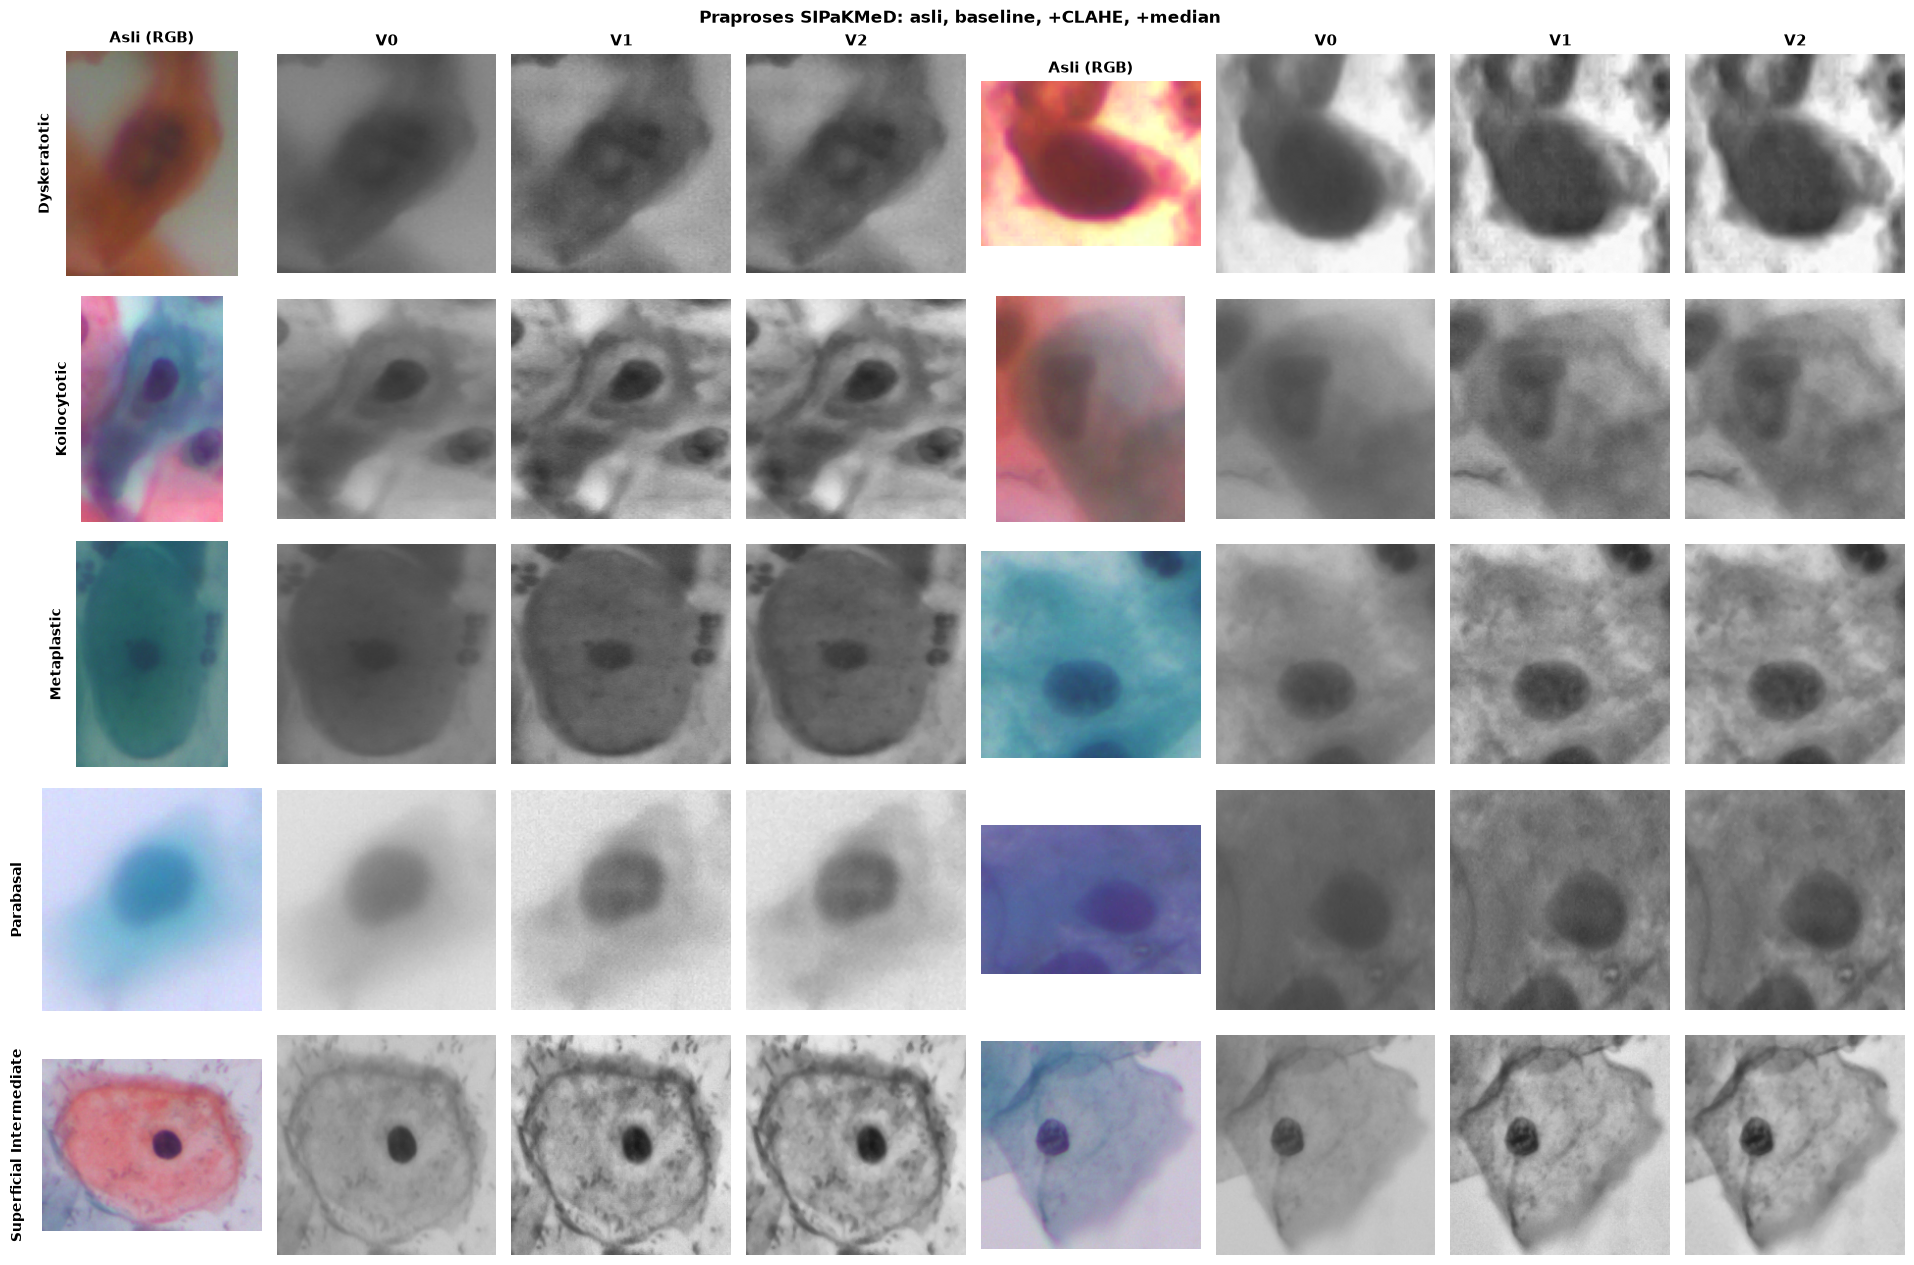

In [6]:
rng = np.random.default_rng(42)
n_contoh = 2
kolom = ["Asli (RGB)", "V0", "V1", "V2"]

fig, axes = plt.subplots(
    len(KELAS), n_contoh * len(kolom),
    figsize=(2.4 * n_contoh * len(kolom), 2.6 * len(KELAS)),
)
axes = np.atleast_2d(axes)

for i, nama in enumerate(KELAS):
    sub = df[df["kelas"] == nama]
    pilih = sub.sample(n=n_contoh, random_state=42)
    for j, (_, baris) in enumerate(pilih.iterrows()):
        mentah = muat_citra(baris["path"])
        panel = [mentah, preprocess(mentah, "V0"), preprocess(mentah, "V1"), preprocess(mentah, "V2")]
        for k, (judul, img) in enumerate(zip(kolom, panel)):
            ax = axes[i, j * len(kolom) + k]
            ax.axis("off")
            if img.ndim == 3:
                ax.imshow(img)
            else:
                ax.imshow(img, cmap="gray", vmin=0, vmax=255)
            if i == 0:
                ax.set_title(judul, fontsize=11, fontweight="bold")
    axes[i, 0].text(-0.08, 0.5, nama.replace("im_", "").replace("-", " "),
                    transform=axes[i, 0].transAxes, rotation=90,
                    va="center", ha="right", fontsize=10, fontweight="bold")

plt.suptitle("Praproses SIPaKMeD: asli, baseline, +CLAHE, +median", fontweight="bold")
plt.tight_layout()
Path(AKAR / "outputs").mkdir(exist_ok=True)
plt.savefig(AKAR / "outputs/before_after_grid.png", dpi=130, bbox_inches="tight")
plt.show()

### Uji urutan: median sebelum vs sesudah CLAHE

V2 memasang median **setelah** CLAHE (membersihkan noise yang ikut terangkat).
V3 memasangnya **sebelum**. Mana yang lebih baik harus diuji, bukan diasumsikan.

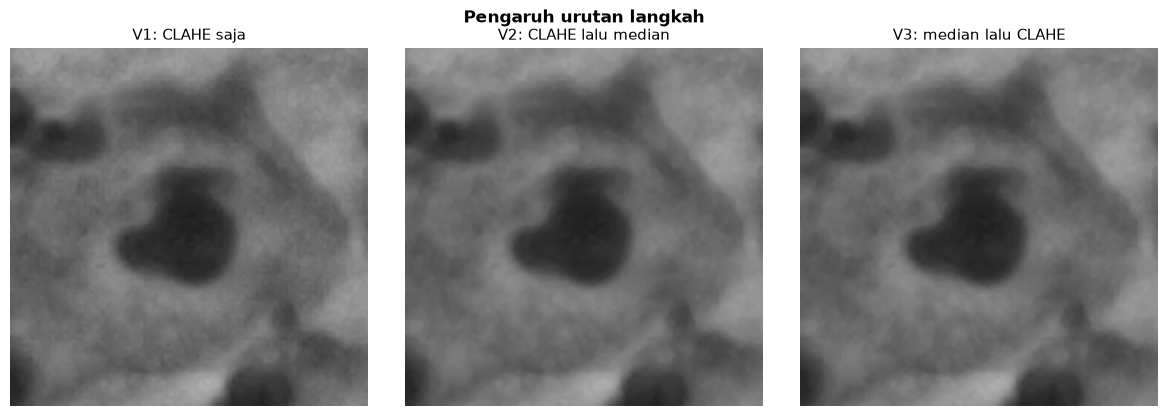

In [7]:
satu = muat_citra(df.iloc[100]["path"])
fig, ax = plt.subplots(1, 3, figsize=(12, 4.2))
for a, (judul, v) in zip(ax, [("V1: CLAHE saja", "V1"), ("V2: CLAHE lalu median", "V2"), ("V3: median lalu CLAHE", "V3")]):
    a.imshow(preprocess(satu, v), cmap="gray", vmin=0, vmax=255)
    a.set_title(judul, fontsize=11)
    a.axis("off")
plt.suptitle("Pengaruh urutan langkah", fontweight="bold")
plt.tight_layout()
plt.savefig(AKAR / "outputs/urutan_langkah.png", dpi=130, bbox_inches="tight")
plt.show()

## 5. Statistik: membuktikan pengaruh tiap tahap

Diukur pada 300 citra sampel berstrata (60 per kelas), supaya cepat tetapi
tetap mewakili kelima kelas.

Metrik yang dipakai:

- **std** naik -> kontras meningkat (efek CLAHE)
- **ketajaman** (variansi Laplacian) turun drastis -> detail hilang (median terlalu besar)
- **p1/p99** mendekati 0/255 -> banyak piksel jenuh (clip_limit terlalu tinggi)

In [8]:
sampel = pd.concat(
    [g.sample(n=60, random_state=42) for _, g in df.groupby("kelas")]
).reset_index(drop=True)
print(f"Sampel: {len(sampel)} citra ({sampel['kelas'].nunique()} kelas x 60)")

baris = []
for _, r in sampel.iterrows():
    mentah = muat_citra(r["path"])
    for v in VARIAN:
        s = statistik(preprocess(mentah, v))
        s.update({"varian": v, "kelas": r["kelas"]})
        baris.append(s)

stat = pd.DataFrame(baris)
ringkas_stat = (
    stat.groupby("varian")[["mean", "std", "p1", "p99", "ketajaman", "entropi"]]
        .mean()
        .reindex(list(VARIAN))
        .round(3)
)
ringkas_stat["keterangan"] = [KETERANGAN_VARIAN[v] for v in ringkas_stat.index]
display(ringkas_stat)

ringkas_stat.to_csv(AKAR / "outputs/statistik_praproses.csv")
print("\nDisimpan: outputs/statistik_praproses.csv")

Sampel: 300 citra (5 kelas x 60)


,mean,std,p1,p99,ketajaman,entropi,keterangan
varian,,,,,,,
V0,138.051,29.913,76.863,193.150,9.671,6.461,resize + grayscale (baseline)
V1,143.216,36.325,65.529,212.408,58.603,6.909,V0 + CLAHE
V2,143.222,36.174,65.887,211.810,25.295,6.885,V1 + median filter (utama)
V3,143.512,36.334,65.916,212.376,32.359,6.896,V0 + median + CLAHE (uji urutan)



Disimpan: outputs/statistik_praproses.csv


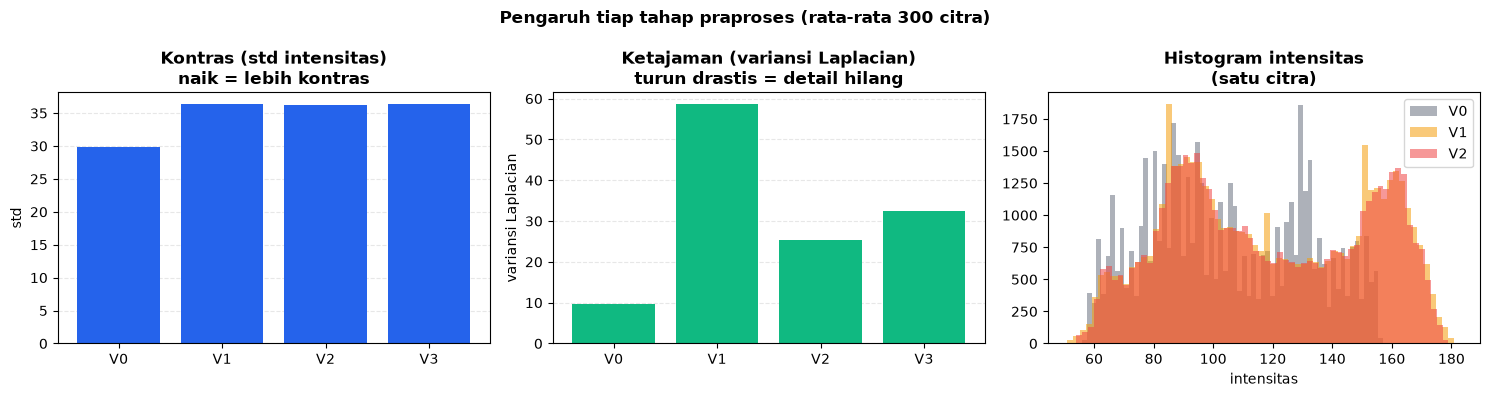

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

v_list = list(VARIAN)
ax[0].bar(v_list, [ringkas_stat.loc[v, "std"] for v in v_list], color="#2563EB")
ax[0].set_title("Kontras (std intensitas)\nnaik = lebih kontras", fontweight="bold")
ax[0].set_ylabel("std")

ax[1].bar(v_list, [ringkas_stat.loc[v, "ketajaman"] for v in v_list], color="#10B981")
ax[1].set_title("Ketajaman (variansi Laplacian)\nturun drastis = detail hilang", fontweight="bold")
ax[1].set_ylabel("variansi Laplacian")

for v, warna in zip(["V0", "V1", "V2"], ["#6B7280", "#F59E0B", "#EF4444"]):
    ax[2].hist(preprocess(muat_citra(sampel.iloc[0]["path"]), v).ravel(),
               bins=64, alpha=0.55, label=v, color=warna)
ax[2].set_title("Histogram intensitas\n(satu citra)", fontweight="bold")
ax[2].set_xlabel("intensitas")
ax[2].legend()

for a in ax[:2]:
    a.grid(axis="y", alpha=0.3, linestyle="--")
    a.set_axisbelow(True)

plt.suptitle("Pengaruh tiap tahap praproses (rata-rata 300 citra)", fontweight="bold")
plt.tight_layout()
plt.savefig(AKAR / "outputs/statistik_praproses.png", dpi=130, bbox_inches="tight")
plt.show()

## 6. Batch seluruh dataset

Empat varian diproses dan disimpan sebagai `.npy` **uint8**.

Ukuran: 4049 x 224 x 224 x 1 byte = **203 MB per varian**. Kalau disimpan
sebagai float64, satu varian saja menjadi 1,6 GB dan Colab akan kehabisan RAM.

Yang disimpan untuk keperluan laporan dan tahap berikutnya: **V0** (baseline,
untuk pembanding) dan **V2** (model utama). V1 dan V3 hanya dihitung
statistiknya pada sampel, tidak perlu disimpan seluruhnya.

In [10]:
Path(AKAR / "data/cache").mkdir(parents=True, exist_ok=True)

waktu_semua = {}
for v in ["V0", "V2"]:
    t0 = time.perf_counter()
    X, waktu = proses_batch(df["path"].tolist(), varian=v, verbose=True)
    total = time.perf_counter() - t0
    waktu_semua[v] = (total, waktu.mean() * 1000)

    np.save(AKAR / f"data/cache/X_{v}.npy", X)
    print(f"{v}: shape={X.shape}, dtype={X.dtype}, "
          f"total={total:.1f}s, rata-rata={waktu.mean()*1000:.1f} ms/citra")
    print(f"     disimpan: data/cache/X_{v}.npy  ({X.nbytes/1e6:.0f} MB)")
    print()

print("Ringkasan waktu:")
for v, (total, per) in waktu_semua.items():
    print(f"  {v}: {total:6.1f} s total, {per:5.1f} ms/citra")

  500/4049 citra ...


  1000/4049 citra ...


  1500/4049 citra ...


  2000/4049 citra ...


  2500/4049 citra ...


  3000/4049 citra ...


... (8 outputs left out)

  3000/4049 citra ...


  3500/4049 citra ...


  4000/4049 citra ...


V2: shape=(4049, 224, 224), dtype=uint8, total=4.5s, rata-rata=1.1 ms/citra
     disimpan: data/cache/X_V2.npy  (203 MB)

Ringkasan waktu:
  V0:    7.3 s total,   1.8 ms/citra
  V2:    4.5 s total,   1.1 ms/citra


## 7. Verifikasi akhir

In [11]:
X2 = np.load(AKAR / "data/cache/X_V2.npy")

cek = {
    "Jumlah citra = 4049": len(X2) == TOTAL_RESMI,
    "Shape (4049, 224, 224)": X2.shape == (TOTAL_RESMI, 224, 224),
    "dtype uint8": X2.dtype == np.uint8,
    "Nilai dalam 0-255": int(X2.min()) >= 0 and int(X2.max()) <= 255,
    "Tidak ada NaN": not np.isnan(X2.astype(np.float32)).any(),
    "metadata sejajar": len(df) == len(X2),
}

for nama, ok in cek.items():
    print(f"  [{'OK' if ok else 'X '}] {nama}")

# Uji keterjajaran: indeks acak, hasil cache harus sama dengan proses ulang
rng = np.random.default_rng(7)
for i in rng.choice(len(df), size=3, replace=False):
    ulang = preprocess(muat_citra(df.iloc[i]["path"]), "V2")
    sama = np.array_equal(X2[i], ulang)
    print(f"  [{'OK' if sama else 'X '}] indeks {i} ({df.iloc[i]['nama_file']}): "
          f"cache == proses ulang")

assert all(cek.values()), "Ada pemeriksaan yang gagal."
print("\nSemua pemeriksaan lolos.")

  [OK] Jumlah citra = 4049
  [OK] Shape (4049, 224, 224)
  [OK] dtype uint8
  [OK] Nilai dalam 0-255
  [OK] Tidak ada NaN
  [OK] metadata sejajar
  [OK] indeks 3824 (096_01): cache == proses ulang
  [OK] indeks 2530 (012_02): cache == proses ulang
  [OK] indeks 2770 (048_08): cache == proses ulang

Semua pemeriksaan lolos.


## 8. Kesimpulan

Isi tabel di bawah ini ke laporan M13 sebagai bukti "pengaruh tahap praproses
dijelaskan", bukan sekadar disebut.

In [12]:
keputusan = pd.DataFrame([
    ["Ukuran citra", "224 x 224", "Ukuran input standar; citra asli 62x48 s/d 531x553 sehingga resize wajib agar skala tekstur GLCM/LBP seragam"],
    ["Interpolasi", "INTER_AREA", "Mayoritas citra lebih besar dari 224 px; INTER_AREA paling baik untuk memperkecil"],
    ["Ruang warna", "Grayscale (RGB2GRAY)", "GLCM dan LBP didefinisikan pada intensitas; sekaligus mengurangi variasi warna pewarnaan antar sediaan"],
    ["CLAHE clipLimit", "2.0", f"std naik dari {ringkas_stat.loc['V0','std']:.1f} ke {ringkas_stat.loc['V1','std']:.1f}; pada clipLimit lebih tinggi noise mulai ter-amplify"],
    ["CLAHE tileGrid", "8 x 8", "Ukuran tile konvensional; cukup lokal untuk menegaskan batas nukleus tanpa memunculkan blok"],
    ["Median ksize", "3", f"ketajaman turun dari {ringkas_stat.loc['V1','ketajaman']:.0f} ke {ringkas_stat.loc['V2','ketajaman']:.0f} (masih wajar, detail tidak hilang)"],
    ["Urutan langkah", "resize - grayscale - CLAHE - median", "Median setelah CLAHE untuk membersihkan noise yang ikut terangkat"],
    ["Varian utama", "V2", "Kontras tinggi dan noise ditekan; V0 disimpan sebagai pembanding untuk membuktikan pengaruh praproses"],
], columns=["Aspek", "Pilihan", "Alasan"])

display(keputusan)

,Aspek,Pilihan,Alasan
0,Ukuran citra,224 x 224,Ukuran input standar; citra asli 62x48 s/d 531...
1,Interpolasi,INTER_AREA,Mayoritas citra lebih besar dari 224 px; INTER...
2,Ruang warna,Grayscale (RGB2GRAY),GLCM dan LBP didefinisikan pada intensitas; se...
3,CLAHE clipLimit,2.0,std naik dari 29.9 ke 36.3; pada clipLimit leb...
4,CLAHE tileGrid,8 x 8,Ukuran tile konvensional; cukup lokal untuk me...
5,Median ksize,3,"ketajaman turun dari 59 ke 25 (masih wajar, de..."
6,Urutan langkah,resize - grayscale - CLAHE - median,Median setelah CLAHE untuk membersihkan noise ...
7,Varian utama,V2,Kontras tinggi dan noise ditekan; V0 disimpan ...
